# Atividade 13 - Rede neural x modelo classico (Encontro 13)

Projeto: recomendacao de treinos personalizados em academia.

Objetivo: treinar uma rede neural simples (`MLPClassifier`) sobre a base tratada do projeto e compara-la, de forma justa, com o modelo classico que o projeto ja usa (`DecisionTreeClassifier(max_depth=5)`) e com o baseline. A pergunta nao e "qual numero e maior", e sim **se a rede neural faz sentido neste projeto**.

**Etapa:** entrega unica (Atividade 13 nao tem esboco).

In [1]:
import os
if not os.path.exists('dataset_academia_tratado.csv'):
    !git clone https://github.com/Vinicasagrande87/fundamentos_ia.git
    %cd fundamentos_ia

## 1. Mesma base, mesma codificacao, mesma divisao

Pipeline identico ao das Atividades 9 e 10: base tratada, `aluno_id` fora das features, one-hot nas categoricas, divisao 80/20 estratificada com `random_state=42`. **Os tres modelos (baseline, arvore e rede) sao treinados neste notebook, sobre exatamente este `X_train` e avaliados neste mesmo `X_test`.**

Metrica principal do projeto (definida na Atividade 10): **recall de Treino D** (falso negativo = recomendar treino mais intenso do que o indicado para quem tem restricao, pouco equipamento ou pouca experiencia). Acuracia e F1-macro aparecem como metricas de apoio.

In [2]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_validate, cross_val_predict
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, recall_score, f1_score, make_scorer, ConfusionMatrixDisplay
from sklearn.exceptions import ConvergenceWarning
from gerar_dataset import recomenda_treino

pd.set_option('display.width', 200)

In [3]:
df = pd.read_csv('dataset_academia_tratado.csv')
X = df.drop(columns=['aluno_id', 'treino_recomendado'])
y = df['treino_recomendado']
X = pd.get_dummies(X, columns=['objetivo', 'nivel_experiencia', 'restricao_fisica', 'equipamento_disponivel'], drop_first=False)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Features:', X.shape[1], '| treino:', len(X_train), '| teste:', len(X_test))
print('Treino D no teste:', (y_test == 'Treino D').sum(), 'alunos')

Features: 15 | treino: 240 | teste: 60
Treino D no teste: 18 alunos


In [4]:
def avalia(nome, modelo):
    """Mesmas metricas, mesmo treino, mesmo teste para todos os modelos."""
    p_tr = modelo.predict(X_train)
    p_te = modelo.predict(X_test)
    return {
        'modelo': nome,
        'acuracia_treino': accuracy_score(y_train, p_tr),
        'acuracia_teste': accuracy_score(y_test, p_te),
        'f1_macro_teste': f1_score(y_test, p_te, average='macro'),
        'recall_D_teste': recall_score(y_test, p_te, labels=['Treino D'], average=None)[0],
    }

## 2. Baseline e modelo classico (arvore de decisao)

In [5]:
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
arvore = DecisionTreeClassifier(max_depth=5, random_state=42).fit(X_train, y_train)

resultados = [avalia('Baseline (most_frequent)', baseline), avalia('Arvore de decisao (max_depth=5)', arvore)]
pd.DataFrame(resultados).round(4)

,modelo,acuracia_treino,acuracia_teste,f1_macro_teste,recall_D_teste
0,Baseline (most_frequent),0.3083,0.3,0.1154,1.0000
1,Arvore de decisao (max_depth=5),0.8875,0.9,0.9010,0.7778


O baseline sempre responde "Treino D" (classe mais frequente), por isso tem recall de D = 1,0 e acuracia 0,30: ele nao aprendeu nada, so mostra que recall de D isolado nao basta, tem que vir junto com a acuracia. A arvore reproduz os numeros das Atividades 9 e 10 (0,90 de acuracia, recall de D 0,7778), o que confirma que a divisao e a mesma.

## 3. Rede neural - primeiras tentativas (e o que deu errado)

### 3.1 Sem padronizacao (so para documentar o problema)

`idade` vai de 16 a 51 e `dias_disponiveis_semana` de 1 a 6, enquanto as colunas one-hot sao 0/1. A rede soma entradas ponderadas, entao a escala diferente desequilibra os gradientes. Esta tentativa **nao** e usada na comparacao; fica aqui como evidencia de por que o `StandardScaler` e obrigatorio.

In [6]:
with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter('always')
    mlp_sem_escala = MLPClassifier(hidden_layer_sizes=(16,), random_state=42).fit(X_train, y_train)
print('Avisos:', [a.category.__name__ for a in avisos])
pd.DataFrame([avalia('MLP SEM padronizacao (descartada)', mlp_sem_escala)]).round(4)

Avisos: ['ConvergenceWarning']


,modelo,acuracia_treino,acuracia_teste,f1_macro_teste,recall_D_teste
0,MLP SEM padronizacao (descartada),0.6375,0.6,0.5639,0.5556


### 3.2 Com padronizacao, mas com o `max_iter` padrao (200 epocas)

O `StandardScaler` fica dentro de um `Pipeline`: ele e ajustado **so no treino** e aplicado no teste com a media/desvio do treino (sem vazamento).

In [7]:
with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter('always')
    mlp_200 = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(16,), random_state=42)).fit(X_train, y_train)
print('Avisos:', [str(a.message)[:90] for a in avisos])
print('Epocas executadas:', mlp_200[-1].n_iter_)
pd.DataFrame([avalia('MLP padronizada, 200 epocas (NAO convergiu)', mlp_200)]).round(4)

Avisos: ["Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converg"]
Epocas executadas: 200


,modelo,acuracia_treino,acuracia_teste,f1_macro_teste,recall_D_teste
0,"MLP padronizada, 200 epocas (NAO convergiu)",0.825,0.9,0.9,0.8889


**ConvergenceWarning.** Com 200 epocas o otimizador para antes de a perda estabilizar. O resultado no teste ate parece melhor que o da arvore (mesma acuracia de 0,90 e recall de D de 0,89 contra 0,78), mas ele vem de uma rede **interrompida no meio do treino**, nao de uma rede treinada. Usar esse numero seria comparar a arvore com um modelo que nao terminou de aprender (e que, por acaso, foi interrompido num ponto favoravel). Por isso ele **nao** entra na comparacao final.

## 4. Escolha da arquitetura (sem olhar o teste)

Para nao escolher a arquitetura "pelo teste" (o que seria um vazamento disfarcado), as candidatas sao comparadas com **validacao cruzada de 5 folds feita so dentro do conjunto de treino** (240 alunos). Todas com `max_iter=3000`, para que convirjam.

In [8]:
recall_D = make_scorer(lambda yt, yp: recall_score(yt, yp, labels=['Treino D'], average=None)[0])

linhas = []
for camadas in [(4,), (8,), (16,), (32,), (16, 8), (64, 32)]:
    m = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=camadas, max_iter=3000, random_state=42))
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter('always')
        r = cross_validate(m, X_train, y_train, cv=5, scoring={'acc': 'accuracy', 'recD': recall_D}, return_train_score=True)
    m.fit(X_train, y_train)
    mlp = m[-1]
    n_param = sum(w.size for w in mlp.coefs_) + sum(b.size for b in mlp.intercepts_)
    linhas.append({
        'camadas escondidas': str(camadas),
        'parametros': n_param,
        'acc_treino (media folds)': r['train_acc'].mean(),
        'acc_validacao (media folds)': r['test_acc'].mean(),
        'recall_D_validacao': r['test_recD'].mean(),
        'avisos_convergencia': sum(issubclass(a.category, ConvergenceWarning) for a in avisos),
    })
arquiteturas = pd.DataFrame(linhas)
arquiteturas.round(3)

,camadas escondidas,parametros,acc_treino (media folds),acc_validacao (media folds),recall_D_validacao,avisos_convergencia
0,"(4,)",84,0.848,0.771,0.717,0
1,"(8,)",164,0.938,0.742,0.690,0
2,"(16,)",324,0.962,0.792,0.784,0
3,"(32,)",644,0.982,0.792,0.823,0
4,"(16, 8)",428,0.983,0.767,0.838,0
5,"(64, 32)",3236,0.994,0.779,0.825,0


**Leitura:**
- Com 4 ou 8 neuronios a rede fica fraca na validacao; a partir de 16 ela acerta mais.
- `(16,)` e `(32,)` empatam na acuracia de validacao (0,792). Escolhemos **`(16,)`**: mesmo resultado com metade dos parametros, e com so 240 alunos de treino cada parametro a mais e mais chance de decorar ruido.
- Redes mais profundas (`(16, 8)`, `(64, 32)`) chegam a 98-99% no treino e **pioram** na validacao: overfitting classico. Sinal de que a base nao comporta uma rede maior.
- Nenhuma candidata gerou aviso de convergencia com `max_iter=3000`.

## 5. Rede neural final

**Arquitetura documentada:**

| Item | Valor |
|---|---|
| Entrada | 15 features (2 numericas + 13 one-hot), padronizadas com `StandardScaler` (ajustado so no treino) |
| Camadas escondidas | **1** camada |
| Neuronios | **16** |
| Ativacao | **ReLU** (camada escondida); saida **softmax** com 4 neuronios (Treino A, B, C, D) |
| Otimizador | Adam, taxa de aprendizado 0,001, regularizacao L2 `alpha=0,0001` (padroes do scikit-learn) |
| Epocas | limite `max_iter=3000`; **convergiu sozinha** (numero exato impresso abaixo) |
| Semente | `random_state=42` |

In [9]:
with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter('always')
    rede = make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(16,), activation='relu', solver='adam', max_iter=3000, random_state=42)
    ).fit(X_train, y_train)

mlp_final = rede[-1]
n_param = sum(w.size for w in mlp_final.coefs_) + sum(b.size for b in mlp_final.intercepts_)
print('Avisos de convergencia:', sum(issubclass(a.category, ConvergenceWarning) for a in avisos))
print('Epocas ate convergir:', mlp_final.n_iter_)
print('Camadas (entrada, escondida, saida):', [mlp_final.coefs_[0].shape[0]] + [c.shape[1] for c in mlp_final.coefs_])
print('Ativacao escondida:', mlp_final.activation, '| saida:', mlp_final.out_activation_)
print('Parametros ajustados:', n_param, '| alunos no treino:', len(X_train))

Avisos de convergencia: 0
Epocas ate convergir: 1479
Camadas (entrada, escondida, saida): [15, 16, 4]
Ativacao escondida: relu | saida: softmax
Parametros ajustados: 324 | alunos no treino: 240


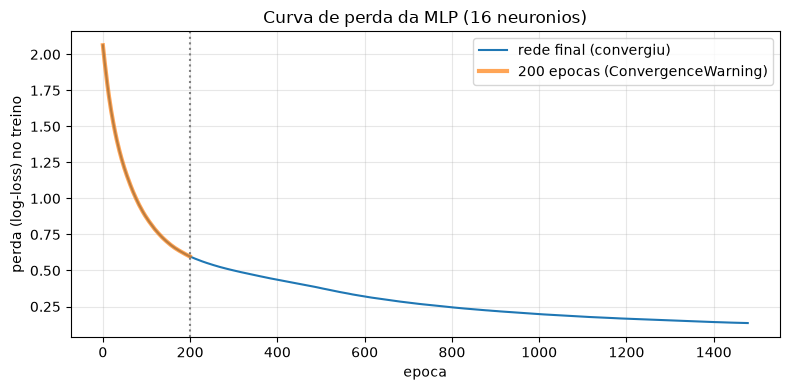

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mlp_final.loss_curve_, label='rede final (convergiu)')
ax.plot(mlp_200[-1].loss_curve_, label='200 epocas (ConvergenceWarning)', lw=3, alpha=0.7)
ax.axvline(200, ls=':', color='gray')
ax.set_xlabel('epoca')
ax.set_ylabel('perda (log-loss) no treino')
ax.set_title('Curva de perda da MLP (16 neuronios)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('curva_perda_atividade13.png', dpi=150, bbox_inches='tight')
plt.show()

A curva mostra o que o aviso queria dizer: em 200 epocas a perda ainda estava caindo. A rede so estabiliza perto da epoca final impressa acima, e nesse ponto a perda de treino ja esta bem baixa: a rede passa a se ajustar aos detalhes (inclusive ao ruido) do treino.

## 6. Comparacao lado a lado (mesmo treino, mesmo teste, mesmas metricas)

In [11]:
resultados.append(avalia('Rede neural MLP (16, ReLU)', rede))
comparacao = pd.DataFrame(resultados).set_index('modelo')
comparacao['gap_treino_teste'] = comparacao['acuracia_treino'] - comparacao['acuracia_teste']
comparacao.round(4)

,acuracia_treino,acuracia_teste,f1_macro_teste,recall_D_teste,gap_treino_teste
modelo,,,,,
Baseline (most_frequent),0.3083,0.3000,0.1154,1.0000,0.0083
Arvore de decisao (max_depth=5),0.8875,0.9000,0.9010,0.7778,-0.0125
"Rede neural MLP (16, ReLU)",0.9458,0.8667,0.8673,0.7222,0.0792


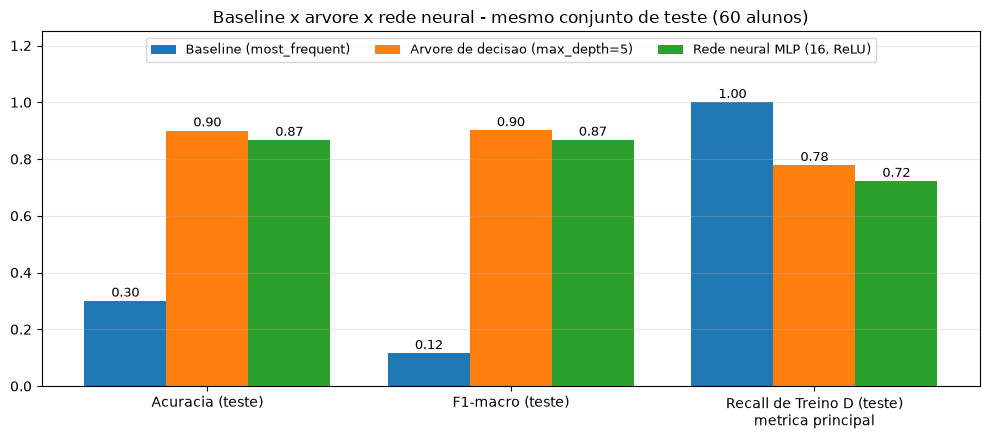

In [12]:
metricas = ['acuracia_teste', 'f1_macro_teste', 'recall_D_teste']
nomes_metricas = ['Acuracia (teste)', 'F1-macro (teste)', 'Recall de Treino D (teste)\nmetrica principal']
fig, ax = plt.subplots(figsize=(10, 4.5))
largura = 0.27
xpos = np.arange(len(metricas))
for i, (nome, linha) in enumerate(comparacao.iterrows()):
    vals = linha[metricas].values.astype(float)
    barras = ax.bar(xpos + (i - 1) * largura, vals, width=largura, label=nome)
    for b, v in zip(barras, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.015, f'{v:.2f}', ha='center', fontsize=9)
ax.set_xticks(xpos)
ax.set_xticklabels(nomes_metricas)
ax.set_ylim(0, 1.25)
ax.set_title('Baseline x arvore x rede neural - mesmo conjunto de teste (60 alunos)')
ax.legend(fontsize=9, loc='upper center', ncol=3)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('comparacao_modelos_atividade13.png', dpi=150, bbox_inches='tight')
plt.show()

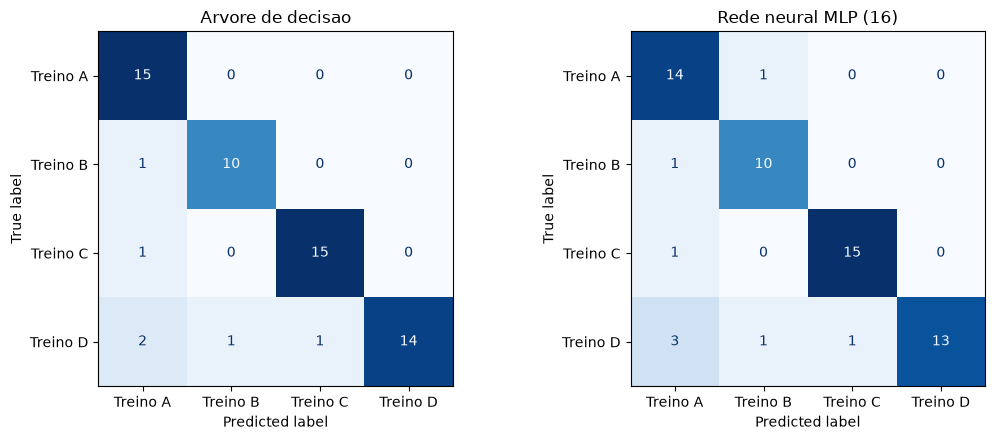

In [13]:
rotulos = sorted(y.unique())
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (nome, m) in zip(axes, [('Arvore de decisao', arvore), ('Rede neural MLP (16)', rede)]):
    ConfusionMatrixDisplay.from_predictions(y_test, m.predict(X_test), labels=rotulos, cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(nome)
plt.tight_layout()
plt.show()

## 7. Confirmacao com validacao cruzada (mesmos 5 folds para todos)

O teste tem so 60 alunos (18 de Treino D): cada aluno vale 1,7 ponto de acuracia e 5,6 pontos de recall de D. Para nao decidir com base em um unico split, repetimos a comparacao com validacao cruzada k=5 sobre a base inteira, **com os mesmos folds para todos os modelos** (`cv=5`, igual a secao 13 da Atividade 10). Incluimos tambem a arvore com `class_weight='balanced'`, item pendente do backlog desde a Atividade 11.

In [14]:
modelos_cv = {
    'Baseline (most_frequent)': DummyClassifier(strategy='most_frequent'),
    'Arvore de decisao (max_depth=5)': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Arvore balanced (max_depth=5)': DecisionTreeClassifier(max_depth=5, random_state=42, class_weight='balanced'),
    'Rede neural MLP (16, ReLU)': make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(16,), max_iter=3000, random_state=42)),
}
linhas = []
with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter('always')
    for nome, m in modelos_cv.items():
        r = cross_validate(m, X, y, cv=5, scoring={'acc': 'accuracy', 'f1': 'f1_macro', 'recD': recall_D}, return_train_score=True)
        linhas.append({
            'modelo': nome,
            'acc_treino': r['train_acc'].mean(),
            'acc_teste': r['test_acc'].mean(),
            'desvio_acc': r['test_acc'].std(),
            'f1_macro': r['test_f1'].mean(),
            'recall_D': r['test_recD'].mean(),
            'gap_treino_teste': r['train_acc'].mean() - r['test_acc'].mean(),
        })
print('Avisos de convergencia na validacao cruzada:', sum(issubclass(a.category, ConvergenceWarning) for a in avisos))
cv_tabela = pd.DataFrame(linhas).set_index('modelo')
cv_tabela.round(4)

Avisos de convergencia na validacao cruzada: 0


,acc_treino,acc_teste,desvio_acc,f1_macro,recall_D,gap_treino_teste
modelo,,,,,,
Baseline (most_frequent),0.3067,0.3067,0.0082,0.1173,1.0000,0.0000
Arvore de decisao (max_depth=5),0.9017,0.8267,0.0291,0.8268,0.7310,0.0750
Arvore balanced (max_depth=5),0.9008,0.8400,0.0291,0.8394,0.7637,0.0608
"Rede neural MLP (16, ReLU)",0.9567,0.8300,0.0245,0.8300,0.8175,0.1267


## 8. A rede corrige o ponto cego encontrado na Atividade 12?

Na Atividade 12, o agrupamento K-means mostrou que os erros da arvore se concentram no grupo **"Emagrecimento com limitacao fisica"** (objetivo emagrecimento + restricao fisica), principalmente falsos negativos de Treino D de alunos iniciantes. Se a rede neural aprendesse a interacao "restricao + iniciante -> D", esse grupo deveria melhorar. Usamos as mesmas previsoes de validacao cruzada da Atividade 12 e separamos erro real de erro por ruido de rotulo com a regra de geracao.

In [15]:
regra = np.array([
    recomenda_treino(r.objetivo, r.nivel_experiencia, r.dias_disponiveis_semana, r.restricao_fisica, r.equipamento_disponivel)
    for r in df.itertuples()
])
rotulo_coerente = (regra == y.values)
grupo_ponto_cego = ((df['objetivo'] == 'Emagrecimento') & (df['restricao_fisica'] != 'Nenhuma')).values

linhas = []
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for nome in ['Arvore de decisao (max_depth=5)', 'Rede neural MLP (16, ReLU)']:
        prev = cross_val_predict(modelos_cv[nome], X, y, cv=5)
        erro_real = (prev != y.values) & rotulo_coerente
        fn_d = erro_real & (y.values == 'Treino D')
        linhas.append({
            'modelo': nome,
            'erros reais (base toda)': erro_real.sum(),
            'falsos neg. reais de D (base toda)': fn_d.sum(),
            'erros reais no grupo': (erro_real & grupo_ponto_cego).sum(),
            'falsos neg. reais de D no grupo': (fn_d & grupo_ponto_cego).sum(),
        })
print('Alunos no grupo Emagrecimento com limitacao fisica:', grupo_ponto_cego.sum())
print('Teto de acuracia imposto pelo ruido de rotulo (regra == rotulo):', rotulo_coerente.mean())
pd.DataFrame(linhas).set_index('modelo')

Alunos no grupo Emagrecimento com limitacao fisica: 36
Teto de acuracia imposto pelo ruido de rotulo (regra == rotulo): 0.92


,erros reais (base toda),falsos neg. reais de D (base toda),erros reais no grupo,falsos neg. reais de D no grupo
modelo,,,,
Arvore de decisao (max_depth=5),28,25,9,7
"Rede neural MLP (16, ReLU)",27,17,8,6


## 9. Analise do resultado

**No split unico, a rede piorou em relacao a arvore.** Mesmo teste de 60 alunos: a arvore tem 0,90 de acuracia e recall de D de 0,78; a rede convergida tem 0,87 e 0,72. Os dois superam com folga o baseline (0,30), entao ambos aprenderam algo.

**Na validacao cruzada (5 folds iguais para todos), a rede empata em acuracia** com a arvore (0,830 contra 0,827, diferenca menor que o desvio entre folds, ~0,03) e fica abaixo da arvore com `class_weight='balanced'` (0,84). O unico ponto em que a rede se destaca e o **recall de Treino D na validacao cruzada** (0,82 contra 0,73 da arvore original e 0,76 da balanced). Mas esse ganho nao se repete no split unico, e com ~18 alunos de Treino D por fold ele corresponde a cerca de 1 ou 2 alunos por fold.

**A rede tambem nao corrige o ponto cego da Atividade 12:** no grupo "Emagrecimento com limitacao fisica" ela continua errando praticamente os mesmos casos (tabela da secao 8). Ela reduz os falsos negativos de D espalhados pela base, mas nao aprende a interacao especifica que falta.

**Hipoteses tecnicas para o resultado:**
1. **Base pequena para a quantidade de parametros.** A rede `(16,)` ajusta 324 parametros com 240 alunos de treino, mais de 1 parametro por exemplo. A arvore com profundidade 5 tem no maximo 32 folhas. A tabela de arquiteturas mostra o efeito: quanto maior a rede, maior o acerto no treino e pior a validacao.
2. **Relacoes simples e de corte, que a arvore captura naturalmente.** A base foi gerada por uma regra do tipo "se nao tem equipamento -> D; se tem restricao e e iniciante ou tem <= 2 dias -> D; ...". Sao cortes por categoria e por limiar de dias, exatamente o formato de uma arvore de decisao. A rede precisa aproximar esses degraus com combinacoes de ReLUs, o que exige mais dados.
3. **Ruido de rotulo de 8% impoe um teto de ~0,92.** Os dois modelos ja estao perto dele no split unico. Uma rede com capacidade sobrando gasta essa capacidade **decorando o ruido** (acuracia de treino 0,95-0,96), o que explica o gap maior.
4. **O problema do recall de D esta nas features, nao no modelo.** Como mostra a secao 8, trocar arvore por rede nao resolve o ponto cego. O que falta e informacao explicita sobre a interacao restricao x nivel, como ja indicado na Atividade 12.

## 10. Treino x teste da rede neural

| | Acuracia treino | Acuracia teste | Diferenca |
|---|---|---|---|
| Rede neural (split unico) | 0,9458 | 0,8667 | 0,0792 |
| Rede neural (validacao cruzada, media dos 5 folds) | 0,9567 | 0,8300 | 0,1267 |
| Arvore (validacao cruzada, para comparacao) | 0,9017 | 0,8267 | 0,0750 |
| Arvore (split unico, para comparacao) | 0,8875 | 0,9000 | -0,0125 |

A rede acerta bem mais no treino do que no teste: **isso e overfitting**. Na validacao cruzada a diferenca da rede (0,127) e quase o dobro da diferenca da arvore (0,075). No split unico a arvore nem tem diferenca (teste ate um pouco melhor que o treino), e a rede tem 0,079. Na pratica, a rede esta aprendendo particularidades dos 240 alunos de treino (inclusive os rotulos ruidosos), que nao se repetem nos alunos novos. Isso combina com a hipotese 1 (parametros demais para a base) e com a tabela de arquiteturas, em que redes maiores aumentam esse gap.

Na arvore, o `max_depth=5` limita a capacidade dela e funciona como protecao contra overfitting.

## 11. Decisao para o projeto final

**Nao vou usar rede neural no projeto final.** O modelo da AS continua sendo a arvore de decisao (`max_depth=5`), e a configuracao `class_weight='balanced'` passa a ser a candidata principal, porque na validacao cruzada ela teve a melhor acuracia (0,84) sem perder interpretabilidade.

Justificativa a partir da base e do problema:
- **Base pequena e tabular (300 alunos, 15 features, 8% de ruido):** a rede nao tem dados suficientes para justificar 324 parametros, e o resultado mostra isso (empate na validacao cruzada, derrota no split unico, overfitting maior).
- **Interpretabilidade e requisito do problema, nao preferencia:** a recomendacao envolve seguranca do aluno (restricao fisica). As analises das Atividades 10 a 12 (regras com `export_text`, atalho por idade, ponto cego "restricao + iniciante") so foram possiveis porque a arvore mostra as regras. A regra de seguranca proposta na Atividade 12 depende de entender por que o modelo errou. Uma rede neural esconde isso.
- **O ganho de recall de D da rede na validacao cruzada nao compensa:** e pequeno (1 a 2 alunos por fold), nao aparece no split unico e nao resolve o ponto cego. O caminho para melhorar o recall de D e mexer nas features (interacao restricao x iniciante) e na regra de seguranca, nao trocar o modelo.

**O que vai para a AS:** esta comparacao entra no relatorio final como a justificativa tecnica para manter a arvore. O numero de referencia passa a ser a validacao cruzada da arvore balanced (0,84). A rede neural fica registrada como alternativa testada e descartada.

## 12. Dificuldades tecnicas e como foram tratadas

1. **ConvergenceWarning com o padrao (`max_iter=200`).** Aumentamos para `max_iter=3000`; a rede converge antes disso pelo criterio de parada do proprio Adam (`tol` e `n_iter_no_change`), sem aviso. A curva de perda (secao 5) mostra que em 200 epocas a perda ainda caia.
2. **O resultado nao convergido parecia melhor.** Com 200 epocas a rede empatava com a arvore no teste (0,90) e tinha recall de D maior (0,89). Foi tentador usar esse numero, mas ele vinha de um treino interrompido, nao de uma escolha. Decidimos comparar apenas a rede convergida e registrar o resultado que pareceria melhor como armadilha.
3. **Rede sem padronizacao.** Sem `StandardScaler`, a rede ficou em 0,60 de acuracia e tambem nao convergiu. O scaler ficou dentro de um `Pipeline` para ser ajustado so no treino (inclusive dentro de cada fold da validacao cruzada).
4. **Escolher a arquitetura sem contaminar o teste.** Testar varias arquiteturas direto no teste e ficar com a melhor seria usar o teste para treinar. A escolha foi feita por validacao cruzada dentro do treino (secao 4).
5. **Teste pequeno demais para decidir.** 60 alunos e 18 de Treino D tornam qualquer diferenca de 1 ou 2 alunos enganosa. Por isso a decisao se apoia tambem na validacao cruzada com os mesmos folds para todos os modelos.

## 13. Limitacoes

- Base sintetica: com alunos reais e mais dados, a relacao entre arvore e rede pode mudar.
- So foram testadas redes rasas com os hiperparametros padrao de otimizacao (taxa de aprendizado, `alpha`). Uma busca mais ampla (regularizacao maior, `early_stopping`) poderia reduzir o overfitting, mas dificilmente mudaria a conclusao com 300 alunos.
- A media da validacao cruzada para recall de D tem alta variancia (poucos alunos de D por fold).